# jaxqg quickstart

This notebook shows how to build a (mostly pre-configured) two-layer model, initialise a
random PV field, integrate, and inspect energies and EKE spectra.

## Setup

In [1]:
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from jaxqg import (
    APE,
    EKE,
    create_two_layer_model,
    define_state,
    plot_isotropic_energy_spectrum,
)
from jaxqg.utils import gaussian_random_field

## Build a two-layer model

In [2]:
model = create_two_layer_model(n_x=512, dt=1800)
grid = model.grid
print(f"Grid: {grid.n_x} x {grid.n_y}, {grid.n_layers} layers")
print(f"Layer thicknesses H: {np.asarray(grid.H)}")
print(f"Deformation radius r_d: {float(grid.r_d):.0f} m")

Grid: 512 x 512, 2 layers
Layer thicknesses H: [ 500. 5000.]
Deformation radius r_d: 15000 m


## Initial condition

The initial PV anomaly is a Gaussian random field with a
$|k|^{-2}$ spectrum.

In [3]:
qh0 = gaussian_random_field(model, 1e-12 * grid.wv**-2)
qh0 = qh0.at[:, grid.wv2_nd < 16].set(0.0)  # remove large scales
state = define_state(model, qh0)
print(f"Initial EKE: {float(EKE(model, state.qh)):.3e} m2/s2")

Initial EKE: 4.230e-04 m2/s2


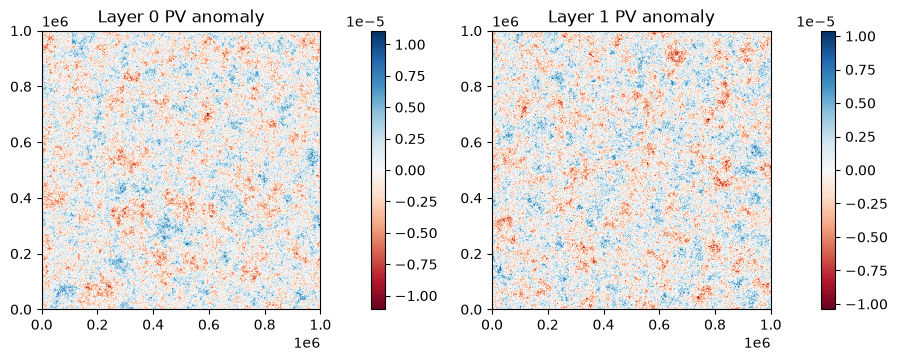

In [4]:
q = np.fft.irfft2(qh0, s=(grid.n_y, grid.n_x))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for i, ax in enumerate(axes):
    pc = ax.pcolormesh(grid.x, grid.y, q[i], cmap="RdBu", norm=mpl.colors.CenteredNorm())
    ax.set_aspect("equal")
    ax.set_title(f"Layer {i} PV anomaly")
    fig.colorbar(pc, ax=ax)
plt.show(fig)

## Integrate

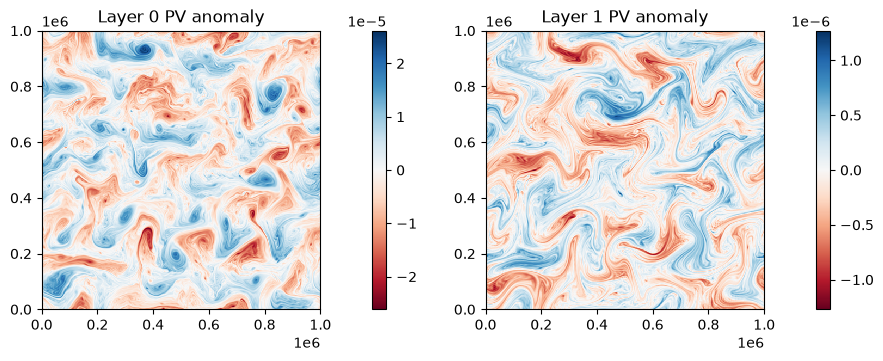

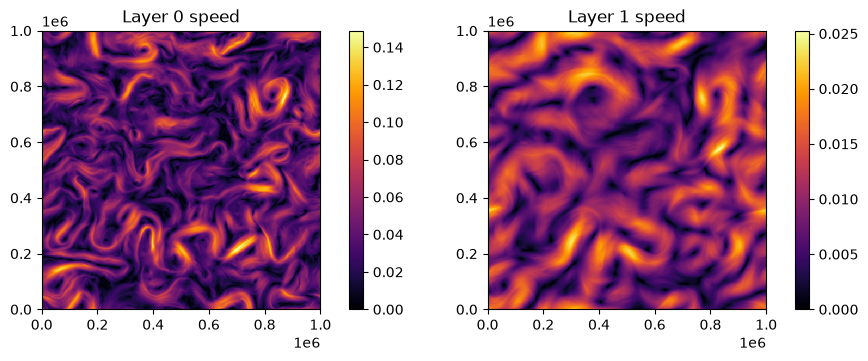

interval 1/5 (365.0 days): 11.349 s


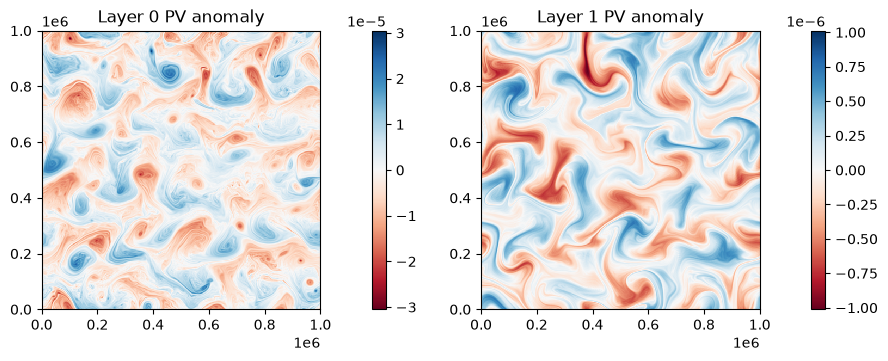

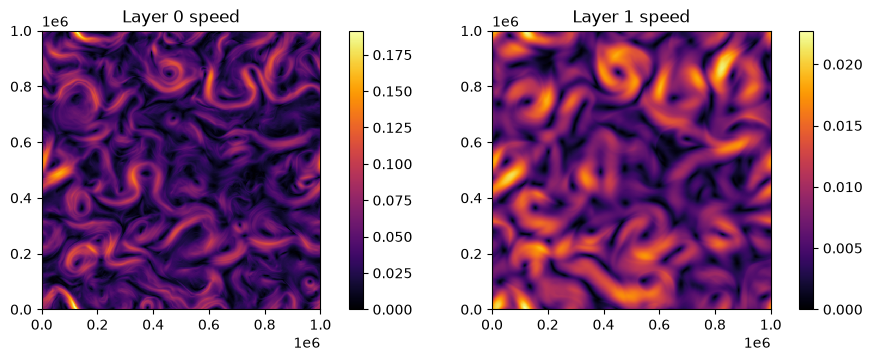

interval 2/5 (730.0 days): 11.009 s


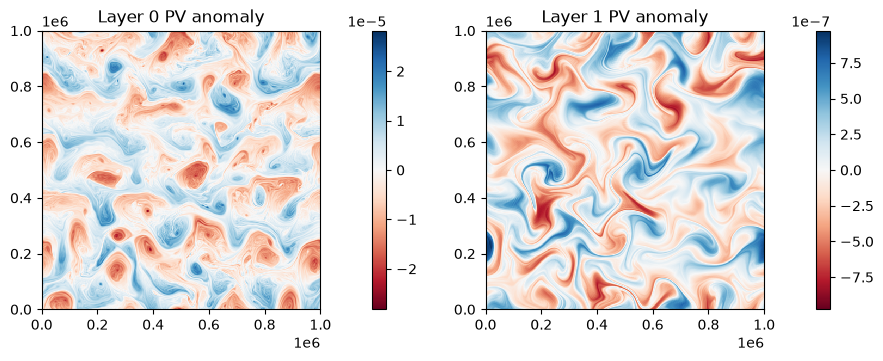

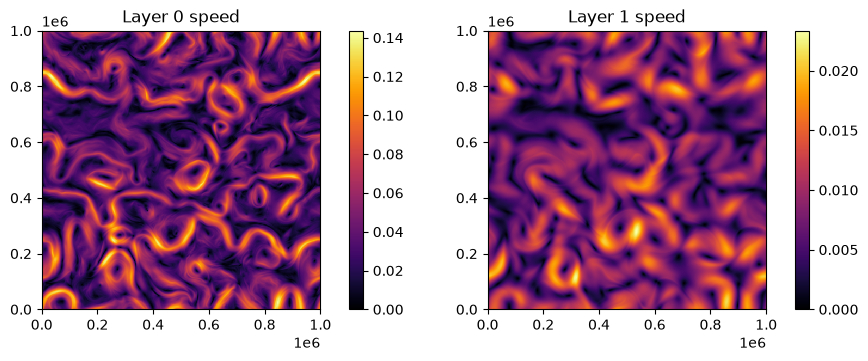

interval 3/5 (1095.0 days): 10.996 s


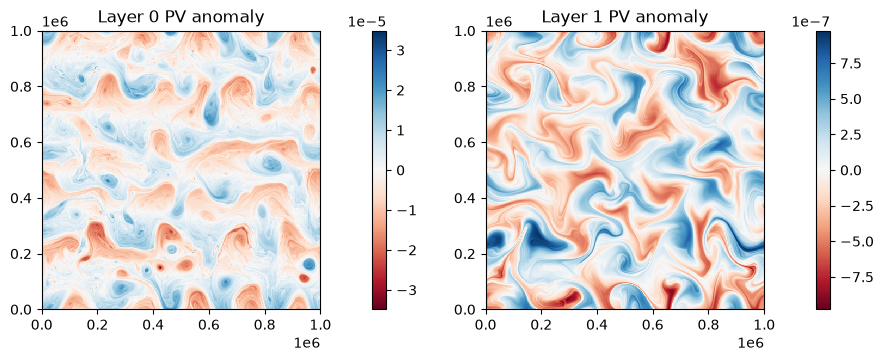

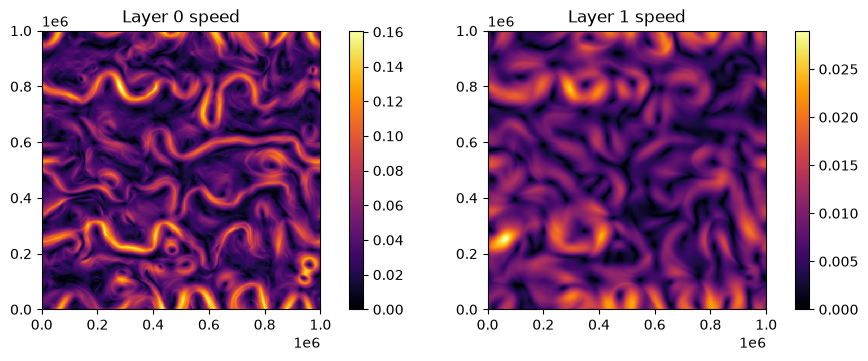

interval 4/5 (1460.0 days): 11.010 s


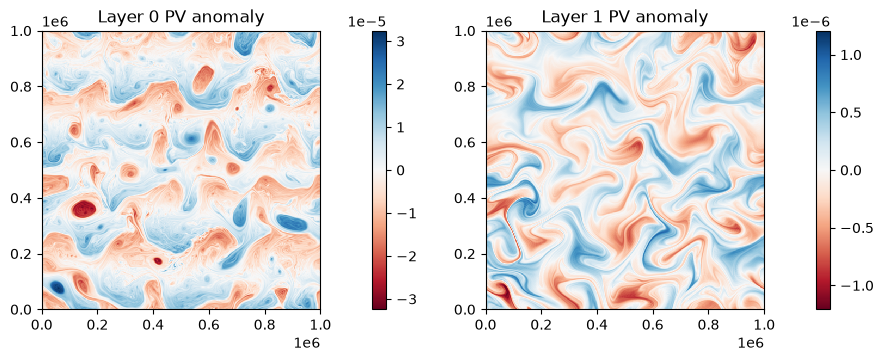

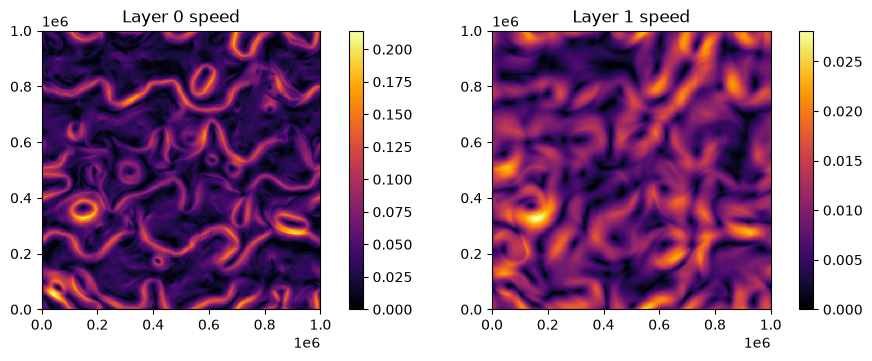

interval 5/5 (1825.0 days): 11.007 s
ran 87600 steps (1825 days at dt = 1800 s)
total time: 55.372 s
EKE: 1.871e-04 m2/s2
APE: 2.683e-04 m2/s2


In [5]:
dt = model.timestepper.dt
n_days = 5 * 365
n_steps = int(n_days * 86400 / dt)
n_snapshots = 5
steps_per_interval = n_steps // n_snapshots

integrate_interval = model.generate_integration_fn(
    steps_per_interval, sample_rate=steps_per_interval, return_final_state=True
)

interval_times = []
cumulative_steps = 0
for i in range(n_snapshots):
    t0 = time.perf_counter()
    state, _ = integrate_interval(state)
    state.qh.block_until_ready()
    elapsed = time.perf_counter() - t0
    interval_times.append(elapsed)
    cumulative_steps += steps_per_interval

    q = np.fft.irfft2(state.qh, s=(grid.n_y, grid.n_x))
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
    for j, ax in enumerate(axes):
        pc = ax.pcolormesh(grid.x, grid.y, q[j], cmap="RdBu",
                           norm=mpl.colors.CenteredNorm())
        ax.set_aspect("equal")
        ax.set_title(f"Layer {j} PV anomaly")
        fig.colorbar(pc, ax=ax)
    plt.show(fig)

    ph = grid._ph_from_qh(state.qh)
    u = np.fft.irfft2(-grid.iky * ph)  # u = -∂ψ/∂y
    v = np.fft.irfft2(grid.ikx * ph)  # v = ∂ψ/∂x
    speed = np.hypot(u, v)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
    for j, ax in enumerate(axes):
        pc = ax.pcolormesh(grid.x, grid.y, speed[j], cmap="inferno", vmin=0.0)
        ax.set_aspect("equal")
        ax.set_title(f"Layer {j} speed")
        fig.colorbar(pc, ax=ax)
    plt.show(fig)
    print(f"interval {i + 1}/{n_snapshots} "
          f"({cumulative_steps * dt / 86400:.1f} days): {elapsed:.3f} s")

final_state = state
print(f"ran {n_steps} steps ({n_days} days at dt = {dt:.0f} s)")
print(f"total time: {sum(interval_times):.3f} s")
print(f"EKE: {float(EKE(model, final_state.qh)):.3e} m2/s2")
print(f"APE: {float(APE(model, final_state.qh)):.3e} m2/s2")

## Isotropic energy spectrum

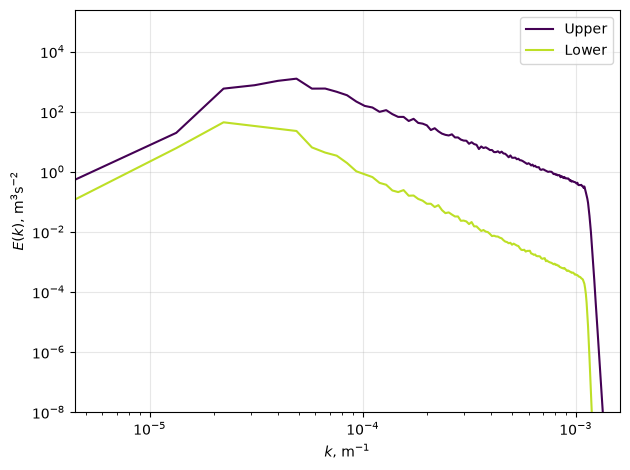

In [6]:
plot_isotropic_energy_spectrum(model, final_state.qh, ymin=1e-8)